In [1]:
import pandas as pd

file_path = r"D:\1.DS project\1.Projects\mechanical dataset\Power Plant Data  Steam Turbine & Boiler Metrics\df_steam_power_plant.parquet"

df = pd.read_parquet(file_path)

print(df.shape)
print(df.head())

(50091, 85)
            Timestamp  m1_dot_steam(kg/s)  Main_steam_temperature(boiler)(K)  \
0  2022-01-01 0:00:00          231.086341                         840.028717   
1  2022-01-01 0:10:00          231.256130                         840.109967   
2  2022-01-01 0:20:00          231.078397                         840.127780   
3  2022-01-01 0:30:00          231.382185                         839.899708   
4  2022-01-01 0:40:00          231.965092                         839.657266   

   Main_steam_pressure(boiler side)(bar)  Reheat_steam_temperature(boiler)(k)  \
0                             144.460130                           838.224076   
1                             144.749073                           838.027278   
2                             145.618184                           838.073357   
3                             146.362118                           838.078633   
4                             146.258564                           838.010907   

   Superheater_desup

In [2]:
file_path = r"D:\1.DS project\1.Projects\mechanical dataset\Power Plant Data  Steam Turbine & Boiler Metrics\part2\final_steam_power_plant.parquet"

final = pd.read_parquet(file_path)

print(final.shape)
print(final.head())

(50091, 112)
            Timestamp  m1_dot_steam(kg/s)  Main_steam_temperature(boiler)(K)  \
0  2022-01-01 0:00:00          231.086341                         840.028717   
1  2022-01-01 0:10:00          231.256130                         840.109967   
2  2022-01-01 0:20:00          231.078397                         840.127780   
3  2022-01-01 0:30:00          231.382185                         839.899708   
4  2022-01-01 0:40:00          231.965092                         839.657266   

   Main_steam_pressure(boiler side)(bar)  Reheat_steam_temperature(boiler)(k)  \
0                             144.460130                           838.224076   
1                             144.749073                           838.027278   
2                             145.618184                           838.073357   
3                             146.362118                           838.078633   
4                             146.258564                           838.010907   

   Superheater_desu

In [85]:
final["Timestamp"] = pd.to_datetime(final["Timestamp"], errors="coerce")

In [3]:
y = final["Nett Load (MW)"]

features = [
    "m1_dot_steam(kg/s)",
    "Main_steam_temperature(boiler)(K)",
    "Main_steam_pressure(boiler side)(bar)",
    #"Reheat_steam_temperature(boiler)(K)",
    "Reheat_steam_temperature(boiler)(k)",
    "P_cond_abs(bar)",
    "m2_extraction(kg/s)",
    "m2_fraction",
    "HP_Turbine_Power(kW)",
    "LP_Turbine_Power(kW)",
    "Pump1_Power(kW)",
    "Pump2_Power(kW)",
    "Boiler_Q(kW)",
    "Reheater_Q(kW)",
    "Condenser_Q(kW)",
    "Thermal_Efficiency",
    "x4_model"
]

In [4]:
import numpy as np
import pandas as pd

numeric_df = final.select_dtypes(include=np.number)

corr_with_net = (
    numeric_df.corr()["Nett Load (MW)"]
    .sort_values(ascending=False)
)

print(corr_with_net)

Nett Load (MW)        1.000000
h4(kJ/kg)             0.011667
O2 Out APH (%)        0.011652
x4_model              0.011639
P_Cond_Vacuum(bar)    0.011619
                        ...   
h8(kJ/kg)_model      -0.013669
Flow rate (KNm3/h)   -0.013704
m8_dot_water(kg/s)   -0.016967
m2_fraction          -0.017972
x5                         NaN
Name: Nett Load (MW), Length: 107, dtype: float64


In [5]:
corr_with_eff = (
    numeric_df.corr()["Thermal_Efficiency"]
    .sort_values(ascending=False)
)

print(corr_with_eff)

Thermal_Efficiency      1.000000
m2_fraction             0.696699
HP Turbine eff (%)      0.458043
HP_Turbine_Power(kW)    0.413803
Model_gross_MW          0.390625
                          ...   
h6(kJ/kg)              -0.785385
x4_model               -0.790838
x4_data                -0.800205
h4(kJ/kg)              -0.804838
x5                           NaN
Name: Thermal_Efficiency, Length: 107, dtype: float64


In [6]:
train_size = int(len(final) * 0.8)

train = final.iloc[:train_size]
test = final.iloc[train_size:]

In [7]:
"Reheat_steam_temperature(boiler)(k)" in final.columns

True

In [8]:
[c for c in final.columns if "Reheat" in c]

['Reheat_steam_temperature(boiler)(k)',
 'Reheater_desuperheating_water_flow(kg/s)',
 'Reheater_Q(kW)']

In [9]:
features = [
    "m1_dot_steam(kg/s)",
    "Main_steam_temperature(boiler)(K)",
    "Main_steam_pressure(boiler side)(bar)",
    "Reheat_steam_temperature(boiler)(k)"
]

In [10]:
X_train = train[features]
y_train = train["Nett Load (MW)"]

X_test = test[features]
y_test = test["Nett Load (MW)"]

In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def evaluate_model(model, X_test, y_test):

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [12]:
X_train = train[features]
y_train = train["Nett Load (MW)"]

X_test = test[features]
y_test = test["Nett Load (MW)"]

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("sklearn imported successfully")

sklearn imported successfully


In [14]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(model, X_test, y_test):

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

In [15]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

metrics = evaluate_model(model, X_test, y_test)

metrics

{'MAE': np.float64(0.9533124714281298),
 'RMSE': np.float64(1.1959383527989398),
 'R2': -0.0002524030416057865}

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

def train_and_evaluate_models(X_train, y_train, X_test, y_test):

    models = {
        "Linear Regression": LinearRegression(),

        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ),

        "Gradient Boosting": GradientBoostingRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ),

        "XGBoost": XGBRegressor(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            random_state=42,
            n_jobs=-1,
            objective="reg:squarederror"
        )
    }

    results = {}
    trained_models = {}

    for name, model in models.items():

        print(f"Training {name}...")

        model.fit(X_train, y_train)

        metrics = evaluate_model(
            model,
            X_test,
            y_test
        )

        results[name] = metrics
        trained_models[name] = model

        print(
            f"MAE: {metrics['MAE']:.4f} | "
            f"RMSE: {metrics['RMSE']:.4f} | "
            f"R²: {metrics['R2']:.4f}"
        )

    results_df = pd.DataFrame(results).T

    return results_df, trained_models

results_df, trained_models = train_and_evaluate_models(
    X_train,
    y_train,
    X_test,
    y_test
)

Training Linear Regression...
MAE: 0.9533 | RMSE: 1.1959 | R²: -0.0003
Training Random Forest...
MAE: 0.9778 | RMSE: 1.2236 | R²: -0.0471
Training Gradient Boosting...
MAE: 0.9546 | RMSE: 1.1972 | R²: -0.0024
Training XGBoost...
MAE: 0.9545 | RMSE: 1.1974 | R²: -0.0028


In [17]:
X_train.describe()

,m1_dot_steam(kg/s),Main_steam_temperature(boiler)(K),Main_steam_pressure(boiler side)(bar),Reheat_steam_temperature(boiler)(k)
count,40072.000000,40072.000000,40072.000000,40072.000000
mean,230.600488,840.354645,142.718211,838.751376
std,1.304036,0.557053,1.179503,0.476963
min,224.759753,837.992746,137.767008,836.868841
25%,229.721634,839.978780,141.916252,838.430670
50%,230.596605,840.354930,142.721711,838.751347
75%,231.471786,840.726933,143.509818,839.071996
max,235.994889,842.702365,147.174428,840.539062


In [18]:
train[features + ["Nett Load (MW)"]].corr()["Nett Load (MW)"].sort_values(ascending=False)

Nett Load (MW)                           1.000000
Reheat_steam_temperature(boiler)(k)      0.009380
Main_steam_temperature(boiler)(K)        0.001546
Main_steam_pressure(boiler side)(bar)   -0.001536
m1_dot_steam(kg/s)                      -0.002766
Name: Nett Load (MW), dtype: float64

In [19]:
for i, col in enumerate(final.columns):
    print(i, col)

0 Timestamp
1 m1_dot_steam(kg/s)
2 Main_steam_temperature(boiler)(K)
3 Main_steam_pressure(boiler side)(bar)
4 Reheat_steam_temperature(boiler)(k)
5 Superheater_desuperheating_water_flow(kg/s)
6 Reheater_desuperheating_water_flow(kg/s)
7 T8(K)
8 m8_dot_water(kg/s)
9 Flue_gas_temperature(k)
10 Boiler oxygen level (%)
11 T1(K)
12 P1(bar)
13 T3(K)
14 P3(bar)
15 Control_stage_pressure(bar)
16 High_exhaust_pressure(bar)
17 P8(bar)
18 P_Cond_Vacuum(bar)
19 Circulating_water_outlet_temperature(K)
20 SO2(kg/m3)
21 Nox(kg/m3)
22 CO(kg/m3)
23 CO2(fraction)
24 O2 (%)
25 Velocity (m/s)
26 Temp.(°k)
27 Pressure(bar)
28 Flow rate (KNm3/h)
29 Opacity (%)
30 Dust(kg/m3)
31 Boiler Eff (%)
32 Entalphy inlet MS (kj/kg)
33 Entropy_Inlet_MS(kJ/kgK)
34 P2(bar)
35 T2(K)
36 h2(kJ/kg)
37 h2s(kJ/kg)
38 ΔP aktual (Kj/Kg)
39 ΔHP isentropis (Kj/Kg)
40 HP Turbine eff (%)
41 O2 in APH (%)
42 O2 Out APH (%)
43 Refference_Temperature(°K)
44 Flue_Gas_in_Temperature(°K)
45 APH Leakage (%)
46 Corrected_Flue_Gas_Out_Tempe

In [20]:
features = [
    # Steam / boiler operating conditions
    "m1_dot_steam(kg/s)",
    "Main_steam_temperature(boiler)(K)",
    "Main_steam_pressure(boiler side)(bar)",
    "Reheat_steam_temperature(boiler)(k)",
    "Superheater_desuperheating_water_flow(kg/s)",
    "Reheater_desuperheating_water_flow(kg/s)",

    # Feedwater / boiler
    "T8(K)",
    "m8_dot_water(kg/s)",
    "Flue_gas_temperature(k)",
    "Boiler oxygen level (%)",
    "Boiler Eff (%)",
    "Coal_Flow(kg/s)",
    "Q_boiler_in(W)",
    "HHV(J/kg)",

    # Turbine conditions
    "Control_stage_pressure(bar)",
    "High_exhaust_pressure(bar)",
    "P_Cond_Vacuum(bar)",
    "HP Turbine eff (%)",

    # Reheat / turbine thermodynamic conditions
    "P2(bar)",
    "T2(K)",
    "P3(bar)",
    "T3(K)",

    # Air / flue gas
    "O2 (%)",
    "Velocity (m/s)",
    "Temp.(°k)",
    "Pressure(bar)",
    "Flow rate (KNm3/h)",
    "Opacity (%)",
    "Dust(kg/m3)",
    "SO2(kg/m3)",
    "Nox(kg/m3)",
    "CO(kg/m3)",
    "CO2(fraction)",

    # Air preheater
    "O2 in APH (%)",
    "O2 Out APH (%)",
    "Refference_Temperature(°K)",
    "Flue_Gas_in_Temperature(°K)",
    "APH Leakage (%)",
    "Corrected_Flue_Gas_Out_Temperature(°K)",
    "APH Effectiveness (%)",

    # Heat / performance indicators
    "NTHR (dimensionless)",
    "NPHR (dimensionless)"
]

X = final[features]
y = final["Nett Load (MW)"]

In [21]:
from sklearn.model_selection import train_test_split

X = final[features]
y = final["Nett Load (MW)"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

results_df, trained_models = train_and_evaluate_models(
    X_train,
    y_train,
    X_test,
    y_test
)

results_df

X_train: (40072, 42)
X_test : (10019, 42)
y_train: (40072,)
y_test : (10019,)
Training Linear Regression...
MAE: 0.9435 | RMSE: 1.1803 | R²: 0.0011
Training Random Forest...
MAE: 0.9192 | RMSE: 1.1492 | R²: 0.0530
Training Gradient Boosting...
MAE: 0.9424 | RMSE: 1.1784 | R²: 0.0043
Training XGBoost...
MAE: 0.9407 | RMSE: 1.1767 | R²: 0.0070


,MAE,RMSE,R2
Linear Regression,0.943513,1.180257,0.001096
Random Forest,0.919244,1.149178,0.053010
Gradient Boosting,0.942397,1.178359,0.004307
XGBoost,0.940737,1.176742,0.007038


In [22]:
import pandas as pd

feature_corr = final[features + ["Nett Load (MW)"]].corr()["Nett Load (MW)"]
feature_corr = feature_corr.sort_values(ascending=False)

print(feature_corr)

Nett Load (MW)                                 1.000000
O2 Out APH (%)                                 0.011652
P_Cond_Vacuum(bar)                             0.011619
Pressure(bar)                                  0.011125
O2 in APH (%)                                  0.010313
Reheat_steam_temperature(boiler)(k)            0.009346
Q_boiler_in(W)                                 0.006450
Temp.(°k)                                      0.006092
Superheater_desuperheating_water_flow(kg/s)    0.005866
Control_stage_pressure(bar)                    0.005510
T3(K)                                          0.004745
SO2(kg/m3)                                     0.004677
Main_steam_pressure(boiler side)(bar)          0.003209
Coal_Flow(kg/s)                                0.002342
Dust(kg/m3)                                    0.001749
Boiler oxygen level (%)                        0.001649
High_exhaust_pressure(bar)                     0.001555
Corrected_Flue_Gas_Out_Temperature(°K)         0

In [23]:
final["Auxiliary_Load(MW)"] = (
    final["Gross Load (MW)"] - final["Nett Load (MW)"]
)

In [35]:
final["Net_Power_Calc(kW)"] = (
    final["HP_Turbine_Power(kW)"]
    + final["LP_Turbine_Power(kW)"]
    - final["Pump1_Power(kW)"]
    - final["Pump2_Power(kW)"]
)

final["Net_Power_Calc(MW)"] = (
    final["Net_Power_Calc(kW)"] / 1000
)

In [36]:
final.head()

,Timestamp,m1_dot_steam(kg/s),Main_steam_temperature(boiler)(K),Main_steam_pressure(boiler side)(bar),Reheat_steam_temperature(boiler)(k),Superheater_desuperheating_water_flow(kg/s),Reheater_desuperheating_water_flow(kg/s),T8(K),m8_dot_water(kg/s),Flue_gas_temperature(k),...,Energy_balance_err(kW),error,filename,traceback,Model_gross_MW,Model_to_plant_ratio,Auxiliary_Load(MW),Net_Power_Calc(kW),Net_Power_Calc(MW),Net_Power_Calc(KW)
0,2022-01-01 0:00:00,231.086341,840.028717,144.460130,838.224076,24.759231,0.981668,503.713896,232.787458,399.706083,...,0.000000e+00,None,None,None,279.706223,0.947384,15.590637,279347.161027,279.347161,279347.161027
1,2022-01-01 0:10:00,231.256130,840.109967,144.749073,838.027278,23.849228,1.208983,503.729426,232.892028,400.170317,...,1.164153e-10,None,None,None,279.811440,0.946835,15.637220,279440.798449,279.440798,279440.798449
2,2022-01-01 0:20:00,231.078397,840.127780,145.618184,838.073357,22.291377,1.170855,503.676694,232.793891,399.805042,...,5.820766e-11,None,None,None,279.545390,0.947310,15.804279,279144.131819,279.144132,279144.131819
3,2022-01-01 0:30:00,231.382185,839.899708,146.362118,838.078633,21.443933,1.010270,503.697290,232.898753,398.554809,...,5.820766e-11,None,None,None,279.864534,0.948296,16.089891,279436.510353,279.436510,279436.510353
4,2022-01-01 0:40:00,231.965092,839.657266,146.258564,838.010907,22.357077,0.897292,503.770138,233.250897,396.928227,...,-5.820766e-11,None,None,None,280.565482,0.948943,16.353189,280140.595082,280.140595,280140.595082


In [37]:
print(
    final[
        [
            "HP_Turbine_Power(kW)",
            "LP_Turbine_Power(kW)",
            "Pump1_Power(kW)",
            "Pump2_Power(kW)",
            "Net_Power_Calc(kW)",
            "Net_Power_Calc(MW)"
        ]
    ].head()
)

   HP_Turbine_Power(kW)  LP_Turbine_Power(kW)  Pump1_Power(kW)  \
0         101457.513989         182508.194163       472.615759   
1         101488.727471         182583.800174       473.631866   
2         101318.915556         182483.510634       472.589432   
3         101324.540323         182801.889968       473.114005   
4         101528.265895         183309.786991       475.128160   

   Pump2_Power(kW)  Net_Power_Calc(kW)  Net_Power_Calc(MW)  
0      4145.931366       279347.161027          279.347161  
1      4158.097330       279440.798449          279.440798  
2      4185.704939       279144.131819          279.144132  
3      4216.805933       279436.510353          279.436510  
4      4222.329643       280140.595082          280.140595  


In [39]:
final["TESPy_vs_Plant_Net_Error(MW)"] = (
    final["Net_Power_Calc(MW)"]
    - final["Nett Load (MW)"]
)

final["TESPy_vs_Plant_Net_Error(%)"] = (
    final["TESPy_vs_Plant_Net_Error(MW)"]
    / final["Nett Load (MW)"]
    * 100
)

print(
    final[
        [
            "Nett Load (MW)",
            "Net_Power_Calc(MW)",
            "TESPy_vs_Plant_Net_Error(MW)",
            "TESPy_vs_Plant_Net_Error(%)"
        ]
    ].describe()
)

       Nett Load (MW)  Net_Power_Calc(MW)  TESPy_vs_Plant_Net_Error(MW)  \
count    50091.000000        50091.000000                  50091.000000   
mean       280.048641          280.034659                     -0.013982   
std          1.190617            1.736848                      2.109917   
min        275.263586          272.110861                     -8.990761   
25%        279.245031          278.866871                     -1.447748   
50%        280.055509          280.035259                     -0.013648   
75%        280.856959          281.192772                      1.399732   
max        284.569521          287.193896                      7.893875   

       TESPy_vs_Plant_Net_Error(%)  
count                 50091.000000  
mean                     -0.003174  
std                       0.753494  
min                      -3.191818  
25%                      -0.515904  
50%                      -0.004877  
75%                       0.500518  
max                       2.

In [40]:
final["Auxiliary_Load(MW)"] = (
    final["Gross Load (MW)"]
    - final["Nett Load (MW)"]
)

In [41]:
final["TESPy_vs_Plant_Abs_Error(MW)"] = (
    final["TESPy_vs_Plant_Net_Error(MW)"].abs()
)

print(
    final["TESPy_vs_Plant_Abs_Error(MW)"].describe()
)

count    50091.000000
mean         1.681830
std          1.274103
min          0.000069
25%          0.660339
50%          1.423667
75%          2.438069
max          8.990761
Name: TESPy_vs_Plant_Abs_Error(MW), dtype: float64


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_actual = final["Nett Load (MW)"]
y_tespy = final["Net_Power_Calc(MW)"]

mae = mean_absolute_error(y_actual, y_tespy)
rmse = np.sqrt(mean_squared_error(y_actual, y_tespy))
r2 = r2_score(y_actual, y_tespy)

print(f"TESPy MAE : {mae:.4f} MW")
print(f"TESPy RMSE: {rmse:.4f} MW")
print(f"TESPy R²  : {r2:.4f}")

TESPy MAE : 1.6818 MW
TESPy RMSE: 2.1099 MW
TESPy R²  : -2.1405


In [43]:
final["TESPy_Error(MW)"] = (
    final["Net_Power_Calc(MW)"]
    - final["Nett Load (MW)"]
)

final["TESPy_Abs_Error(MW)"] = (
    final["TESPy_Error(MW)"].abs()
)

In [44]:
error_features = [
    "m1_dot_steam(kg/s)",
    "T1(K)",
    "P1(bar)",
    "T3(K)",
    "P3(bar)",
    "P_Cond_Vacuum(bar)",
    "HP Turbine eff (%)",
    "Boiler Eff (%)",
    "Coal_Flow(kg/s)",
    "Q_boiler_in(W)",
    "Gross Load (MW)"
]

corr = final[error_features + ["TESPy_Error(MW)"]].corr()["TESPy_Error(MW)"]
corr.sort_values()

P_Cond_Vacuum(bar)   -0.215181
Boiler Eff (%)       -0.009403
Q_boiler_in(W)       -0.007321
Gross Load (MW)       0.002195
Coal_Flow(kg/s)       0.003360
T3(K)                 0.041315
P3(bar)               0.052164
T1(K)                 0.060929
P1(bar)               0.094944
HP Turbine eff (%)    0.187515
m1_dot_steam(kg/s)    0.749759
TESPy_Error(MW)       1.000000
Name: TESPy_Error(MW), dtype: float64

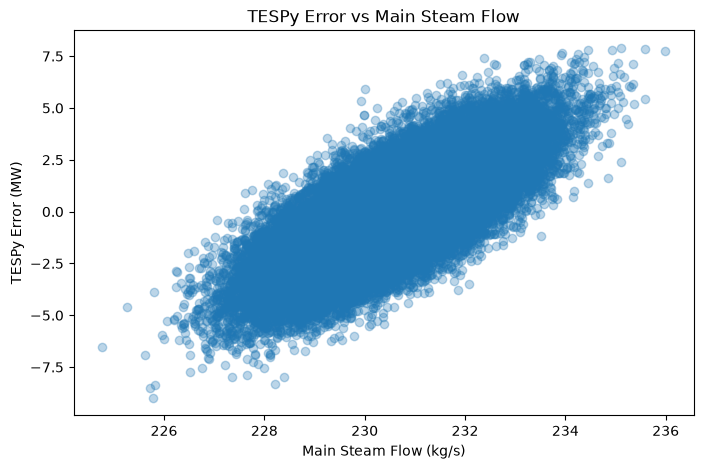

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    final["m1_dot_steam(kg/s)"],
    final["TESPy_Error(MW)"],
    alpha=0.3
)

plt.xlabel("Main Steam Flow (kg/s)")
plt.ylabel("TESPy Error (MW)")
plt.title("TESPy Error vs Main Steam Flow")

plt.show()

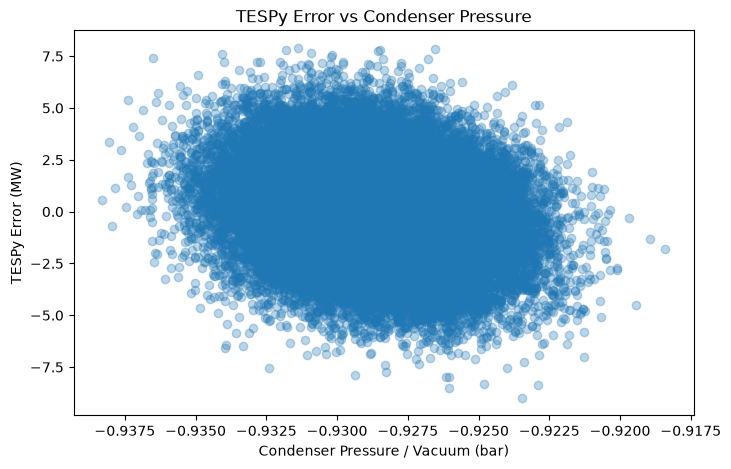

In [46]:
plt.figure(figsize=(8, 5))

plt.scatter(
    final["P_Cond_Vacuum(bar)"],
    final["TESPy_Error(MW)"],
    alpha=0.3
)

plt.xlabel("Condenser Pressure / Vacuum (bar)")
plt.ylabel("TESPy Error (MW)")
plt.title("TESPy Error vs Condenser Pressure")

plt.show()

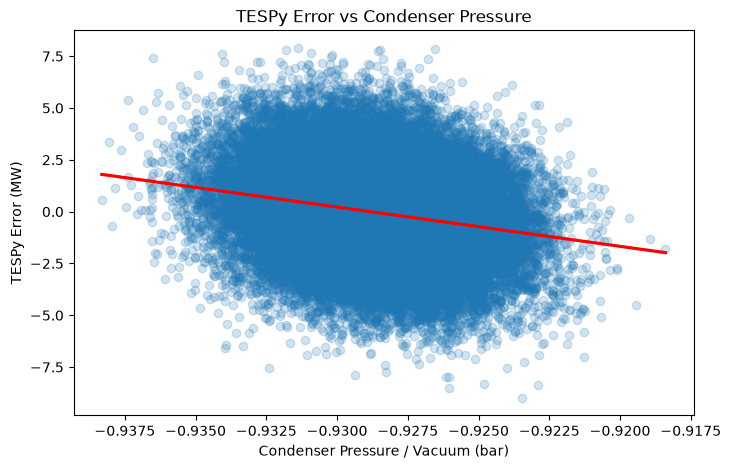

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.regplot(
    data=final,
    x="P_Cond_Vacuum(bar)",
    y="TESPy_Error(MW)",
    scatter_kws={"alpha": 0.2},
    line_kws={"color": "red"}
)

plt.xlabel("Condenser Pressure / Vacuum (bar)")
plt.ylabel("TESPy Error (MW)")
plt.title("TESPy Error vs Condenser Pressure")

plt.show()

In [48]:
final["TESPy_Abs_Error(%)"] = (
    final["TESPy_Abs_Error(MW)"]
    / final["Nett Load (MW)"]
    * 100
)

print(final["TESPy_Abs_Error(%)"].describe())

count    50091.000000
mean         0.600566
std          0.455056
min          0.000025
25%          0.235690
50%          0.508616
75%          0.869937
max          3.191818
Name: TESPy_Abs_Error(%), dtype: float64


In [49]:
print("Error > 1 MW:",
      (final["TESPy_Abs_Error(MW)"] > 1).mean() * 100)

print("Error > 2 MW:",
      (final["TESPy_Abs_Error(MW)"] > 2).mean() * 100)

print("Error > 5 MW:",
      (final["TESPy_Abs_Error(MW)"] > 5).mean() * 100)

Error > 1 MW: 63.0891776965922
Error > 2 MW: 34.58904793276238
Error > 5 MW: 1.8047154179393503


In [50]:
final["TESPy_Error(MW)"] = (
    final["Net_Power_Calc(MW)"]
    - final["Nett Load (MW)"]
)

In [51]:
features = [
    # Steam / boiler
    "m1_dot_steam(kg/s)",
    "Main_steam_temperature(boiler)(K)",
    "Main_steam_pressure(boiler side)(bar)",
    "Reheat_steam_temperature(boiler)(k)",
    "Superheater_desuperheating_water_flow(kg/s)",
    "Reheater_desuperheating_water_flow(kg/s)",

    # Feedwater / boiler
    "T8(K)",
    "m8_dot_water(kg/s)",
    "Flue_gas_temperature(k)",
    "Boiler oxygen level (%)",
    "Boiler Eff (%)",
    "Coal_Flow(kg/s)",
    "HHV(J/kg)",

    # Turbine
    "Control_stage_pressure(bar)",
    "High_exhaust_pressure(bar)",
    "P_Cond_Vacuum(bar)",
    "HP Turbine eff (%)",

    # Reheat
    "P2(bar)",
    "T2(K)",
    "P3(bar)",
    "T3(K)",

    # Air / flue gas
    "O2 (%)",
    "Velocity (m/s)",
    "Temp.(°k)",
    "Pressure(bar)",
    "Flow rate (KNm3/h)",
    "Opacity (%)",
    "Dust(kg/m3)",
    "SO2(kg/m3)",
    "Nox(kg/m3)",
    "CO(kg/m3)",
    "CO2(fraction)",

    # Air preheater
    "O2 in APH (%)",
    "O2 Out APH (%)",
    "Refference_Temperature(°K)",
    "Flue_Gas_in_Temperature(°K)",
    "APH Leakage (%)",
    "Corrected_Flue_Gas_Out_Temperature(°K)",
    "APH Effectiveness (%)",

    # Plant performance
    "NTHR (dimensionless)",
    "NPHR (dimensionless)"
]

In [52]:
from sklearn.model_selection import train_test_split

X = final[features]
y = final["TESPy_Error(MW)"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(40072, 41)
(10019, 41)


In [53]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(model, X_test, y_test):

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

metrics = evaluate_model(model, X_test, y_test)

metrics

{'MAE': np.float64(0.9632619110923769),
 'RMSE': np.float64(1.2024726961706684),
 'R2': 0.6754209359689596}

In [54]:
residual_pred = model.predict(X_test)

final_test = final.loc[X_test.index].copy()

final_test["Predicted_TESPy_Error(MW)"] = residual_pred

final_test["Corrected_Power(MW)"] = (
    final_test["Net_Power_Calc(MW)"]
    - final_test["Predicted_TESPy_Error(MW)"]
)

In [55]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_actual = final_test["Nett Load (MW)"]
y_corrected = final_test["Corrected_Power(MW)"]

mae = mean_absolute_error(y_actual, y_corrected)
rmse = np.sqrt(mean_squared_error(y_actual, y_corrected))
r2 = r2_score(y_actual, y_corrected)

print(f"Corrected MAE : {mae:.4f} MW")
print(f"Corrected RMSE: {rmse:.4f} MW")
print(f"Corrected R²  : {r2:.4f}")

Corrected MAE : 0.9633 MW
Corrected RMSE: 1.2025 MW
Corrected R²  : -0.0369


In [56]:
final = final.sort_values("Timestamp")

split_index = int(len(final) * 0.8)

train = final.iloc[:split_index]
test = final.iloc[split_index:]

X_train = train[features]
y_train = train["TESPy_Error(MW)"]

X_test = test[features]
y_test = test["TESPy_Error(MW)"]

In [58]:
final = final.sort_values("Timestamp").reset_index(drop=True)

split_index = int(len(final) * 0.8)

train = final.iloc[:split_index].copy()
test = final.iloc[split_index:].copy()

print("Train:", train.shape)
print("Test :", test.shape)

print("Train period:")
print(train["Timestamp"].min(), "→", train["Timestamp"].max())

print("\nTest period:")
print(test["Timestamp"].min(), "→", test["Timestamp"].max())

Train: (40072, 122)
Test : (10019, 122)
Train period:
2022-01-01 0:00:00 → 2022-10-06 15:30:00

Test period:
2022-10-06 15:40:00 → 2022-12-14 9:50:00


In [59]:
X_train = train[features]
y_train = train["TESPy_Error(MW)"]

X_test = test[features]
y_test = test["TESPy_Error(MW)"]

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=42)

In [60]:
residual_pred = model.predict(X_test)

test["Predicted_TESPy_Error(MW)"] = residual_pred

test["Corrected_Power(MW)"] = (
    test["Net_Power_Calc(MW)"]
    - test["Predicted_TESPy_Error(MW)"]
)

In [61]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_actual = test["Nett Load (MW)"]
y_corrected = test["Corrected_Power(MW)"]

mae = mean_absolute_error(y_actual, y_corrected)
rmse = np.sqrt(mean_squared_error(y_actual, y_corrected))
r2 = r2_score(y_actual, y_corrected)

print(f"Time-based Corrected MAE : {mae:.4f} MW")
print(f"Time-based Corrected RMSE: {rmse:.4f} MW")
print(f"Time-based Corrected R²  : {r2:.4f}")

Time-based Corrected MAE : 0.9949 MW
Time-based Corrected RMSE: 1.2467 MW
Time-based Corrected R²  : -0.0852


In [63]:
import pandas as pd

importance = pd.Series(
    model.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance.head(15))

m1_dot_steam(kg/s)                          0.573504
P_Cond_Vacuum(bar)                          0.052265
HP Turbine eff (%)                          0.047528
P2(bar)                                     0.032004
P3(bar)                                     0.010672
T3(K)                                       0.009853
m8_dot_water(kg/s)                          0.008348
CO2(fraction)                               0.008281
Temp.(°k)                                   0.008181
High_exhaust_pressure(bar)                  0.008111
Opacity (%)                                 0.008109
Pressure(bar)                               0.008086
CO(kg/m3)                                   0.008044
HHV(J/kg)                                   0.008018
Reheater_desuperheating_water_flow(kg/s)    0.007964
dtype: float64


In [65]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=features
).sort_values(ascending=False)

print(perm_importance.head(15))

m1_dot_steam(kg/s)    1.025154
P_Cond_Vacuum(bar)    0.111316
HP Turbine eff (%)    0.083716
P2(bar)               0.051939
P3(bar)               0.004308
T3(K)                 0.001026
Coal_Flow(kg/s)       0.000770
Flow rate (KNm3/h)    0.000699
m8_dot_water(kg/s)    0.000590
O2 Out APH (%)        0.000463
Dust(kg/m3)           0.000418
T8(K)                 0.000411
Opacity (%)           0.000386
HHV(J/kg)             0.000369
O2 (%)                0.000330
dtype: float64


In [66]:
X_test_sample = X_test.sample(
    n=3000,
    random_state=42
)

y_test_sample = y_test.loc[X_test_sample.index]

perm = permutation_importance(
    model,
    X_test_sample,
    y_test_sample,
    n_repeats=3,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=1
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=features
).sort_values(ascending=False)

print(perm_importance.head(15))

m1_dot_steam(kg/s)                   1.074957
P_Cond_Vacuum(bar)                   0.117117
HP Turbine eff (%)                   0.079540
P2(bar)                              0.049051
P3(bar)                              0.004327
T3(K)                                0.001899
APH Leakage (%)                      0.001235
Coal_Flow(kg/s)                      0.000970
SO2(kg/m3)                           0.000908
O2 in APH (%)                        0.000886
NTHR (dimensionless)                 0.000854
CO(kg/m3)                            0.000827
Main_steam_temperature(boiler)(K)    0.000814
m8_dot_water(kg/s)                   0.000641
Flue_Gas_in_Temperature(°K)          0.000413
dtype: float64


In [69]:
selected_features = [
    "m1_dot_steam(kg/s)",
    "P_Cond_Vacuum(bar)",
    "HP Turbine eff (%)",
    "P2(bar)",
    "P3(bar)",
    "T3(K)",
    "m8_dot_water(kg/s)",
    "Coal_Flow(kg/s)",
    "Flow rate (KNm3/h)",
    "O2 Out APH (%)",
    "HHV(J/kg)"
]

# Sort chronologically
final = final.sort_values("Timestamp").reset_index(drop=True)

# Features and target
X = final[selected_features]
y = final["TESPy_Error(MW)"]

# 80% earlier data → training
# 20% later data → testing
split_index = int(len(final) * 0.8)

X_train = X.iloc[:split_index]
X_test  = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test  = y.iloc[split_index:]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# Random Forest
from sklearn.ensemble import RandomForestRegressor

model_selected = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model_selected.fit(X_train, y_train)

# Predict TESPy residual
residual_pred = model_selected.predict(X_test)

X_train: (40072, 11)
X_test : (10019, 11)
y_train: (40072,)
y_test : (10019,)


In [70]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, residual_pred)
rmse = np.sqrt(mean_squared_error(y_test, residual_pred))
r2 = r2_score(y_test, residual_pred)

print(f"MAE  = {mae:.4f} MW")
print(f"RMSE = {rmse:.4f} MW")
print(f"R²   = {r2:.4f}")

MAE  = 0.9932 MW
RMSE = 1.2460 MW
R²   = 0.6470


In [71]:
mae_corrected = mean_absolute_error(
    test["Nett Load (MW)"],
    test["Corrected_Power(MW)"]
)

rmse_corrected = np.sqrt(
    mean_squared_error(
        test["Nett Load (MW)"],
        test["Corrected_Power(MW)"]
    )
)

r2_corrected = r2_score(
    test["Nett Load (MW)"],
    test["Corrected_Power(MW)"]
)

print(f"Corrected Power MAE  = {mae_corrected:.4f} MW")
print(f"Corrected Power RMSE = {rmse_corrected:.4f} MW")
print(f"Corrected Power R²   = {r2_corrected:.4f}")

Corrected Power MAE  = 0.9949 MW
Corrected Power RMSE = 1.2467 MW
Corrected Power R²   = -0.0852


In [72]:
print(
    test[
        [
            "Net_Power_Calc(MW)",
            "Nett Load (MW)",
            "Predicted_TESPy_Error(MW)",
            "Corrected_Power(MW)"
        ]
    ].head()
)

       Net_Power_Calc(MW)  Nett Load (MW)  Predicted_TESPy_Error(MW)  \
40072          281.976082      277.581617                   2.136084   
40073          281.119919      277.875441                   0.638418   
40074          281.029646      278.635970                   1.401895   
40075          280.811551      279.797115                   1.018286   
40076          281.341609      280.792215                   1.797125   

       Corrected_Power(MW)  
40072           279.839998  
40073           280.481501  
40074           279.627751  
40075           279.793265  
40076           279.544484  


In [73]:
print(
    test["Predicted_TESPy_Error(MW)"].describe()
)

count    10019.000000
mean        -0.021173
std          1.678834
min         -6.032923
25%         -1.162241
50%         -0.012786
75%          1.094257
max          5.732580
Name: Predicted_TESPy_Error(MW), dtype: float64


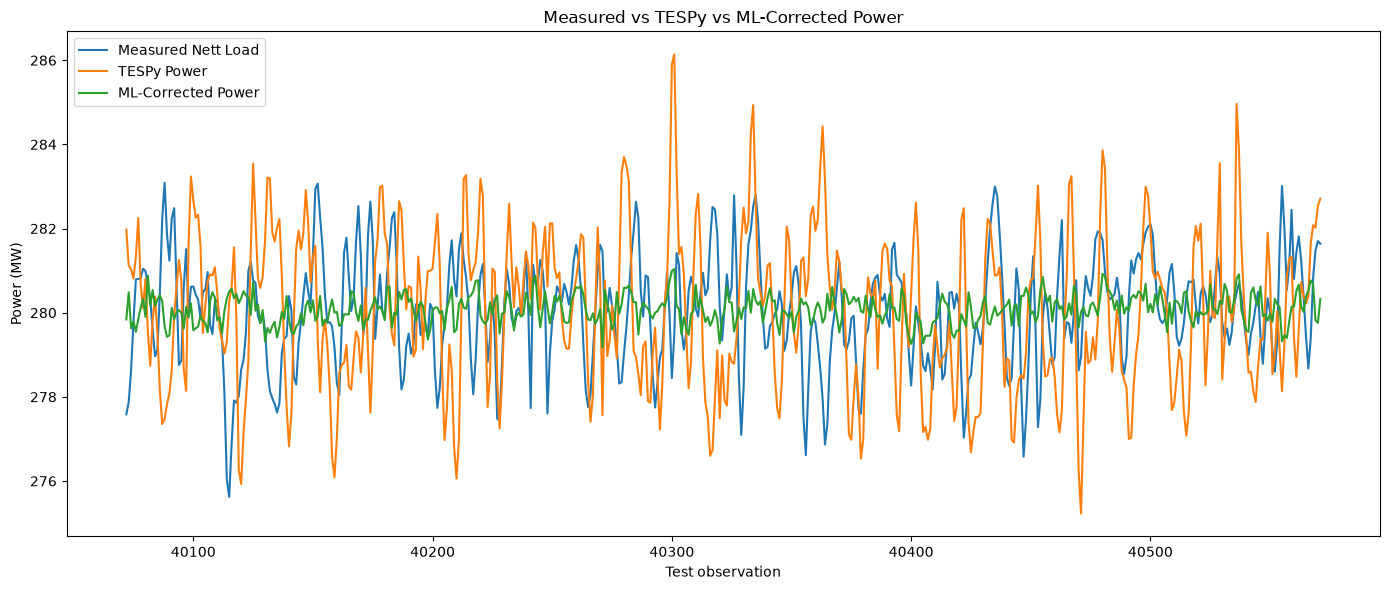

In [74]:
import matplotlib.pyplot as plt

plot_data = test.iloc[:500].copy()

plt.figure(figsize=(14, 6))

plt.plot(
    plot_data.index,
    plot_data["Nett Load (MW)"],
    label="Measured Nett Load"
)

plt.plot(
    plot_data.index,
    plot_data["Net_Power_Calc(MW)"],
    label="TESPy Power"
)

plt.plot(
    plot_data.index,
    plot_data["Corrected_Power(MW)"],
    label="ML-Corrected Power"
)

plt.xlabel("Test observation")
plt.ylabel("Power (MW)")
plt.title("Measured vs TESPy vs ML-Corrected Power")
plt.legend()
plt.tight_layout()
plt.show()

In [75]:
print("Measured std:",
      test["Nett Load (MW)"].std())

print("TESPy std:",
      test["Net_Power_Calc(MW)"].std())

print("ML-Corrected std:",
      test["Corrected_Power(MW)"].std())

Measured std: 1.1968244707318885
TESPy std: 1.7278088123337254
ML-Corrected std: 0.35416443203499004


In [76]:
print(
    "Measured vs TESPy:",
    test["Nett Load (MW)"].corr(
        test["Net_Power_Calc(MW)"]
    )
)

print(
    "Measured vs ML-Corrected:",
    test["Nett Load (MW)"].corr(
        test["Corrected_Power(MW)"]
    )
)

Measured vs TESPy: 0.004790094718786898
Measured vs ML-Corrected: 0.004711873461019912


In [77]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

raw_mae = mean_absolute_error(
    test["Nett Load (MW)"],
    test["Net_Power_Calc(MW)"]
)

raw_rmse = np.sqrt(
    mean_squared_error(
        test["Nett Load (MW)"],
        test["Net_Power_Calc(MW)"]
    )
)

raw_r2 = r2_score(
    test["Nett Load (MW)"],
    test["Net_Power_Calc(MW)"]
)

print(f"Raw TESPy MAE  = {raw_mae:.4f} MW")
print(f"Raw TESPy RMSE = {raw_rmse:.4f} MW")
print(f"Raw TESPy R²   = {raw_r2:.4f}")

Raw TESPy MAE  = 1.6610 MW
Raw TESPy RMSE = 2.0975 MW
Raw TESPy R²   = -2.0717


In [78]:
print(final["Timestamp"].min())
print(final["Timestamp"].max())

print("\nFirst 5:")
print(
    final[
        ["Timestamp", "Nett Load (MW)", "Net_Power_Calc(MW)"]
    ].head()
)

print("\nLast 5:")
print(
    final[
        ["Timestamp", "Nett Load (MW)", "Net_Power_Calc(MW)"]
    ].tail()
)

2022-01-01 0:00:00
2022-12-14 9:50:00

First 5:
            Timestamp  Nett Load (MW)  Net_Power_Calc(MW)
0  2022-01-01 0:00:00      279.649889          279.347161
1  2022-01-01 0:10:00      279.885623          279.440798
2  2022-01-01 0:20:00      279.289591          279.144132
3  2022-01-01 0:30:00      279.033867          279.436510
4  2022-01-01 0:40:00      279.307840          280.140595

Last 5:
                Timestamp  Nett Load (MW)  Net_Power_Calc(MW)
50086  2022-12-14 9:10:00      279.239921          281.090742
50087  2022-12-14 9:20:00      278.755892          280.916531
50088  2022-12-14 9:30:00      277.758352          280.052643
50089  2022-12-14 9:40:00      278.250618          279.951500
50090  2022-12-14 9:50:00      280.089096          280.051396


In [86]:
time_diff = final["Timestamp"].diff()

print(time_diff.describe())
print("\nMost common intervals:")
print(time_diff.value_counts().head(10))

count                     50090
mean     0 days 00:09:59.245358
std      0 days 03:10:06.680858
min           -1 days +02:10:00
25%             0 days 00:10:00
50%             0 days 00:10:00
75%             0 days 00:10:00
max             0 days 18:10:00
Name: Timestamp, dtype: object

Most common intervals:
Timestamp
0 days 00:10:00      48351
0 days 09:10:00        348
-1 days +05:10:00      348
0 days 18:10:00        348
-1 days +02:10:00      347
0 days 14:10:00        347
-1 days +05:40:00        1
Name: count, dtype: int64


In [88]:
print(final["Timestamp"].min())
print(final["Timestamp"].max())

print("\nFirst 5:")
print(
    final[
        ["Timestamp", "Nett Load (MW)", "Net_Power_Calc(MW)"]
    ].head()
)

print("\nLast 5:")
print(
    final[
        ["Timestamp", "Nett Load (MW)", "Net_Power_Calc(MW)"]
    ].tail()
)

2022-01-01 00:00:00
2022-12-14 20:20:00

First 5:
            Timestamp  Nett Load (MW)  Net_Power_Calc(MW)
0 2022-01-01 00:00:00      279.649889          279.347161
1 2022-01-01 00:10:00      279.885623          279.440798
2 2022-01-01 00:20:00      279.289591          279.144132
3 2022-01-01 00:30:00      279.033867          279.436510
4 2022-01-01 00:40:00      279.307840          280.140595

Last 5:
                Timestamp  Nett Load (MW)  Net_Power_Calc(MW)
50086 2022-12-14 09:10:00      279.239921          281.090742
50087 2022-12-14 09:20:00      278.755892          280.916531
50088 2022-12-14 09:30:00      277.758352          280.052643
50089 2022-12-14 09:40:00      278.250618          279.951500
50090 2022-12-14 09:50:00      280.089096          280.051396


In [87]:
time_diff = final["Timestamp"].diff()

print(time_diff.describe())
print("\nMost common intervals:")
print(time_diff.value_counts().head(10))

count                     50090
mean     0 days 00:09:59.245358
std      0 days 03:10:06.680858
min           -1 days +02:10:00
25%             0 days 00:10:00
50%             0 days 00:10:00
75%             0 days 00:10:00
max             0 days 18:10:00
Name: Timestamp, dtype: object

Most common intervals:
Timestamp
0 days 00:10:00      48351
0 days 09:10:00        348
-1 days +05:10:00      348
0 days 18:10:00        348
-1 days +02:10:00      347
0 days 14:10:00        347
-1 days +05:40:00        1
Name: count, dtype: int64


In [89]:
bad_intervals = time_diff[
    (time_diff != pd.Timedelta(minutes=10))
]

print("Number of non-10-minute intervals:", len(bad_intervals))

print(
    final.loc[
        bad_intervals.index,
        ["Timestamp", "Nett Load (MW)", "Net_Power_Calc(MW)"]
    ].head(30)
)

Number of non-10-minute intervals: 1740
              Timestamp  Nett Load (MW)  Net_Power_Calc(MW)
0   2022-01-01 00:00:00      279.649889          279.347161
6   2022-01-01 10:00:00      280.524122          280.474737
66  2022-01-01 01:00:00      279.782875          280.916604
72  2022-01-01 20:00:00      279.580585          285.433276
96  2022-01-01 02:00:00      279.327992          279.551973
144 2022-01-02 00:00:00      280.558904          278.788631
150 2022-01-02 10:00:00      281.868656          279.795743
210 2022-01-02 01:00:00      280.295407          279.601904
216 2022-01-02 20:00:00      280.908592          281.587903
240 2022-01-02 02:00:00      281.306803          279.679486
288 2022-01-03 00:00:00      280.820515          279.239904
294 2022-01-03 10:00:00      278.900489          279.430677
354 2022-01-03 01:00:00      281.809471          278.526366
360 2022-01-03 20:00:00      280.753196          283.365449
384 2022-01-03 02:00:00      280.901219          281.113003


In [90]:
backward = time_diff[time_diff < pd.Timedelta(0)]

print("Backward intervals:", len(backward))

print(
    final.loc[
        backward.index,
        ["Timestamp", "Nett Load (MW)", "Net_Power_Calc(MW)"]
    ].head(20)
)

Backward intervals: 696
               Timestamp  Nett Load (MW)  Net_Power_Calc(MW)
66   2022-01-01 01:00:00      279.782875          280.916604
96   2022-01-01 02:00:00      279.327992          279.551973
210  2022-01-02 01:00:00      280.295407          279.601904
240  2022-01-02 02:00:00      281.306803          279.679486
354  2022-01-03 01:00:00      281.809471          278.526366
384  2022-01-03 02:00:00      280.901219          281.113003
498  2022-01-04 01:00:00      281.748567          280.004000
528  2022-01-04 02:00:00      280.993660          282.062231
642  2022-01-05 01:00:00      278.192180          278.410354
672  2022-01-05 02:00:00      279.960862          279.258606
786  2022-01-06 01:00:00      278.215332          281.279196
816  2022-01-06 02:00:00      279.382664          277.345131
930  2022-01-07 01:00:00      278.689886          280.263929
960  2022-01-07 02:00:00      281.433277          281.901899
1074 2022-01-08 01:00:00      279.408007          280.774698


In [91]:
print(
    "Duplicate timestamps:",
    final["Timestamp"].duplicated().sum()
)

Duplicate timestamps: 0


In [92]:
print(
    final["Timestamp"]
    .dt.hour
    .value_counts()
    .sort_index()
)

Timestamp
0     2088
1     2088
2     2088
3     2088
4     2088
5     2088
6     2088
7     2088
8     2088
9     2088
10    2088
11    2088
12    2088
13    2088
14    2088
15    2088
16    2088
17    2088
18    2088
19    2088
20    2085
21    2082
22    2082
23    2082
Name: count, dtype: int64


In [93]:
print(
    final[
        ["Timestamp", "Nett Load (MW)", "Net_Power_Calc(MW)"]
    ].head(100).to_string(index=False)
)

          Timestamp  Nett Load (MW)  Net_Power_Calc(MW)
2022-01-01 00:00:00      279.649889          279.347161
2022-01-01 00:10:00      279.885623          279.440798
2022-01-01 00:20:00      279.289591          279.144132
2022-01-01 00:30:00      279.033867          279.436510
2022-01-01 00:40:00      279.307840          280.140595
2022-01-01 00:50:00      279.381772          280.508808
2022-01-01 10:00:00      280.524122          280.474737
2022-01-01 10:10:00      279.640847          279.708007
2022-01-01 10:20:00      279.012477          279.200657
2022-01-01 10:30:00      279.541080          279.619077
2022-01-01 10:40:00      280.071304          280.061675
2022-01-01 10:50:00      278.636027          279.433504
2022-01-01 11:00:00      277.232158          278.552032
2022-01-01 11:10:00      278.705198          278.258445
2022-01-01 11:20:00      280.310657          278.420003
2022-01-01 11:30:00      279.972934          278.248373
2022-01-01 11:40:00      279.715032          278

In [94]:
expected_per_day = 24 * 6

observations_per_day = (
    final.groupby(final["Timestamp"].dt.date)
    .size()
)

print(observations_per_day.describe())

print("\nDays with unexpected number of observations:")
print(
    observations_per_day[
        observations_per_day != expected_per_day
    ].head(20)
)

count    348.000000
mean     143.939655
std        1.125718
min      123.000000
25%      144.000000
50%      144.000000
75%      144.000000
max      144.000000
dtype: float64

Days with unexpected number of observations:
Timestamp
2022-12-14    123
dtype: int64


In [95]:
final = final.sort_values("Timestamp").reset_index(drop=True)

In [98]:
print("Is Timestamp sorted?")
print(final["Timestamp"].is_monotonic_increasing)

print(
    final.loc[
        55:75,
        ["Timestamp", "Nett Load (MW)", "Net_Power_Calc(MW)"]
    ].to_string(index=True)
)

print(
    final["Timestamp"].head(20).tolist()
)

print(final["Timestamp"].dtype)

print(
    final["Timestamp"]
    .sort_values()
    .head(20)
    .tolist()
)

Is Timestamp sorted?
True
             Timestamp  Nett Load (MW)  Net_Power_Calc(MW)
55 2022-01-01 09:10:00      279.491474          279.241333
56 2022-01-01 09:20:00      280.200259          279.936828
57 2022-01-01 09:30:00      280.839619          280.616288
58 2022-01-01 09:40:00      280.866195          280.722643
59 2022-01-01 09:50:00      280.693792          280.614984
60 2022-01-01 10:00:00      280.524122          280.474737
61 2022-01-01 10:10:00      279.640847          279.708007
62 2022-01-01 10:20:00      279.012477          279.200657
63 2022-01-01 10:30:00      279.541080          279.619077
64 2022-01-01 10:40:00      280.071304          280.061675
65 2022-01-01 10:50:00      278.636027          279.433504
66 2022-01-01 11:00:00      277.232158          278.552032
67 2022-01-01 11:10:00      278.705198          278.258445
68 2022-01-01 11:20:00      280.310657          278.420003
69 2022-01-01 11:30:00      279.972934          278.248373
70 2022-01-01 11:40:00      27

In [100]:
final["Timestamp"].is_monotonic_increasing

final = final.sort_values("Timestamp").reset_index(drop=True)

In [101]:
selected_features = [
    "m1_dot_steam(kg/s)",
    "P_Cond_Vacuum(bar)",
    "HP Turbine eff (%)",
    "P2(bar)",
    "P3(bar)",
    "T3(K)",
    "m8_dot_water(kg/s)",
    "Coal_Flow(kg/s)",
    "Flow rate (KNm3/h)",
    "O2 Out APH (%)",
    "HHV(J/kg)"
]

X = final[selected_features]
y = final["TESPy_Error(MW)"]

split_index = int(len(final) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("\nTraining period:")
print(final["Timestamp"].iloc[:split_index].min())
print(final["Timestamp"].iloc[:split_index].max())

print("\nTesting period:")
print(final["Timestamp"].iloc[split_index:].min())
print(final["Timestamp"].iloc[split_index:].max())

Training: (40072, 11)
Testing: (10019, 11)

Training period:
2022-01-01 00:00:00
2022-10-06 06:30:00

Testing period:
2022-10-06 06:40:00
2022-12-14 20:20:00


In [102]:
from sklearn.ensemble import RandomForestRegressor

model_selected = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model_selected.fit(X_train, y_train)

residual_pred = model_selected.predict(X_test)

In [103]:
test = final.iloc[split_index:].copy()

test["Predicted_TESPy_Error(MW)"] = residual_pred

test["Corrected_Power(MW)"] = (
    test["Net_Power_Calc(MW)"]
    - test["Predicted_TESPy_Error(MW)"]
)

In [104]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_actual = test["Nett Load (MW)"]

mae = mean_absolute_error(
    y_actual,
    test["Corrected_Power(MW)"]
)

rmse = np.sqrt(
    mean_squared_error(
        y_actual,
        test["Corrected_Power(MW)"]
    )
)

r2 = r2_score(
    y_actual,
    test["Corrected_Power(MW)"]
)

print(f"Corrected Power MAE:  {mae:.4f} MW")
print(f"Corrected Power RMSE: {rmse:.4f} MW")
print(f"Corrected Power R²:   {r2:.4f}")

Corrected Power MAE:  0.9933 MW
Corrected Power RMSE: 1.2445 MW
Corrected Power R²:   -0.0832


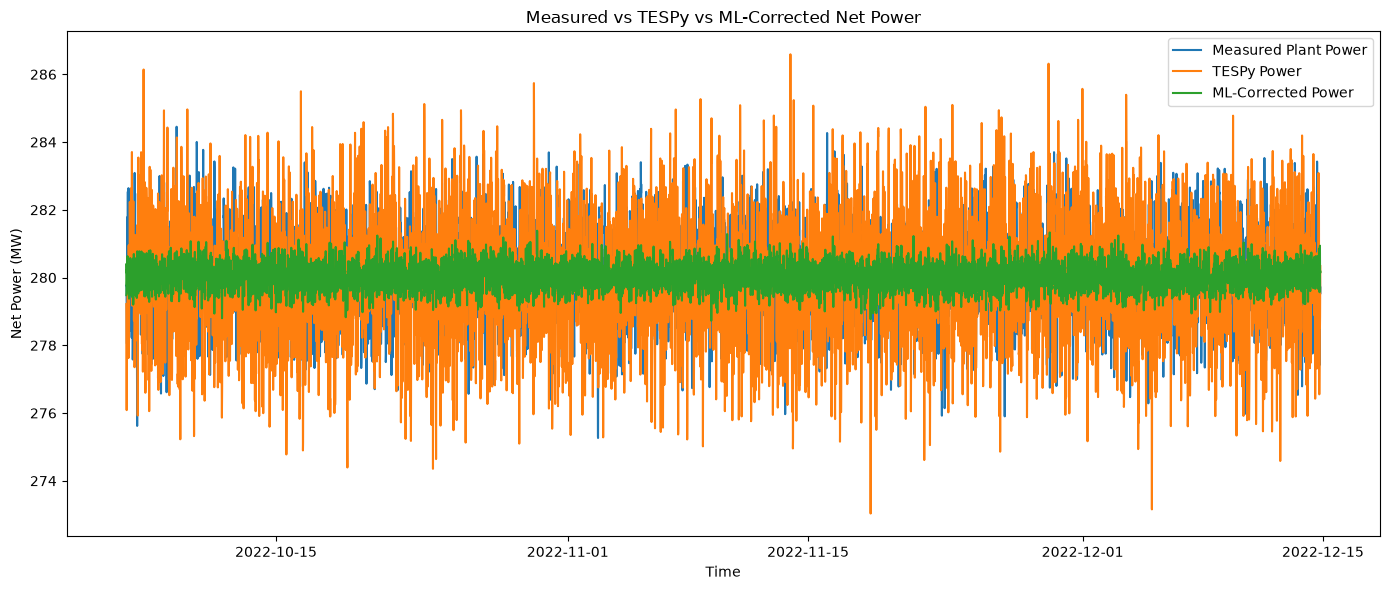

In [105]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    test["Timestamp"],
    test["Nett Load (MW)"],
    label="Measured Plant Power"
)

plt.plot(
    test["Timestamp"],
    test["Net_Power_Calc(MW)"],
    label="TESPy Power"
)

plt.plot(
    test["Timestamp"],
    test["Corrected_Power(MW)"],
    label="ML-Corrected Power"
)

plt.xlabel("Time")
plt.ylabel("Net Power (MW)")
plt.title("Measured vs TESPy vs ML-Corrected Net Power")
plt.legend()
plt.tight_layout()
plt.show()

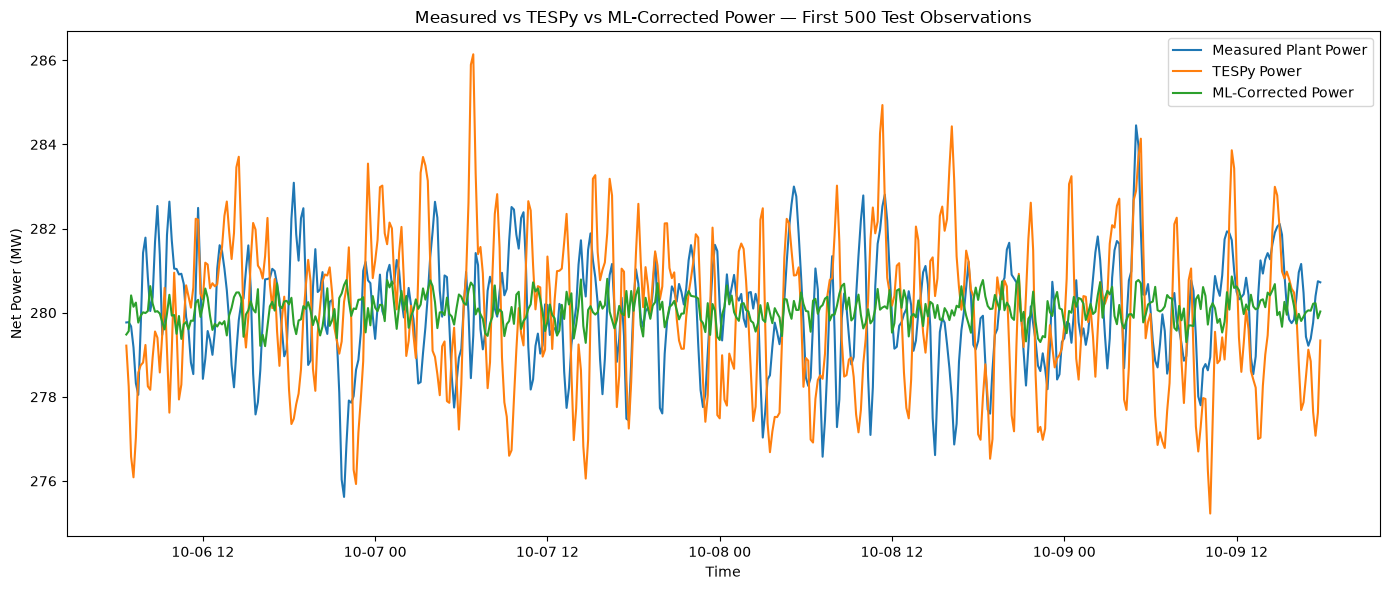

In [106]:
plot_data = test.iloc[:500]

plt.figure(figsize=(14, 6))

plt.plot(
    plot_data["Timestamp"],
    plot_data["Nett Load (MW)"],
    label="Measured Plant Power"
)

plt.plot(
    plot_data["Timestamp"],
    plot_data["Net_Power_Calc(MW)"],
    label="TESPy Power"
)

plt.plot(
    plot_data["Timestamp"],
    plot_data["Corrected_Power(MW)"],
    label="ML-Corrected Power"
)

plt.xlabel("Time")
plt.ylabel("Net Power (MW)")
plt.title("Measured vs TESPy vs ML-Corrected Power — First 500 Test Observations")
plt.legend()
plt.tight_layout()
plt.show()

In [107]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Actual plant power
y_actual = test["Nett Load (MW)"]

# Raw TESPy
tespy_pred = test["Net_Power_Calc(MW)"]

# ML-corrected TESPy
ml_pred = test["Corrected_Power(MW)"]

# Metrics
tespy_mae = mean_absolute_error(y_actual, tespy_pred)
tespy_rmse = np.sqrt(mean_squared_error(y_actual, tespy_pred))
tespy_r2 = r2_score(y_actual, tespy_pred)

ml_mae = mean_absolute_error(y_actual, ml_pred)
ml_rmse = np.sqrt(mean_squared_error(y_actual, ml_pred))
ml_r2 = r2_score(y_actual, ml_pred)

# Improvement
mae_improvement = (tespy_mae - ml_mae) / tespy_mae * 100
rmse_improvement = (tespy_rmse - ml_rmse) / tespy_rmse * 100

print("RAW TESPy")
print(f"MAE:  {tespy_mae:.4f} MW")
print(f"RMSE: {tespy_rmse:.4f} MW")
print(f"R²:   {tespy_r2:.4f}")

print("\nML-CORRECTED TESPy")
print(f"MAE:  {ml_mae:.4f} MW")
print(f"RMSE: {ml_rmse:.4f} MW")
print(f"R²:   {ml_r2:.4f}")

print("\nIMPROVEMENT")
print(f"MAE improvement:  {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

RAW TESPy
MAE:  1.6587 MW
RMSE: 2.0949 MW
R²:   -2.0692

ML-CORRECTED TESPy
MAE:  0.9933 MW
RMSE: 1.2445 MW
R²:   -0.0832

IMPROVEMENT
MAE improvement:  40.11%
RMSE improvement: 40.59%


In [109]:
final["Corrected_Power(MW)"] = np.nan

final.loc[test.index, "Corrected_Power(MW)"] = test["Corrected_Power(MW)"]

In [110]:
dashboard_columns = [
    "Timestamp",

    # TESPy / operating inputs
    "m1_dot_steam(kg/s)",
    "T1(K)",
    "P1(bar)",
    "P2(bar)",
    "P3(bar)",
    "T3(K)",
    "P_Cond_Vacuum(bar)",
    "m8_dot_water(kg/s)",
    "Coal_Flow(kg/s)",
    "Flow rate (KNm3/h)",
    "O2 Out APH (%)",
    "HHV(J/kg)",
    "HP Turbine eff (%)",

    # Plant measurement
    "Gross Load (MW)",
    "Nett Load (MW)",

    # TESPy results
    "Net_Power_Calc(MW)",
    "Thermal_Efficiency",

    # ML results
    "TESPy_Error(MW)",
    "Corrected_Power(MW)"
]

dashboard_df = final[dashboard_columns].copy()

In [111]:
from IPython.display import FileLink

dashboard_df.to_parquet("dashboard_df_steam_power_plant.parquet", index=False)

FileLink("dashboard_df_steam_power_plant.parquet")

C:\Users\Enter Store\dashboard_df_steam_power_plant.parquet

In [113]:
final

,Timestamp,m1_dot_steam(kg/s),Main_steam_temperature(boiler)(K),Main_steam_pressure(boiler side)(bar),Reheat_steam_temperature(boiler)(k),Superheater_desuperheating_water_flow(kg/s),Reheater_desuperheating_water_flow(kg/s),T8(K),m8_dot_water(kg/s),Flue_gas_temperature(k),...,Net_Power_Calc(kW),Net_Power_Calc(MW),Net_Power_Calc(KW),TESPy_vs_Plant_Net_Error(MW),TESPy_vs_Plant_Net_Error(%),TESPy_vs_Plant_Abs_Error(MW),TESPy_Error(MW),TESPy_Abs_Error(MW),TESPy_Abs_Error(%),Corrected_Power(MW)
0,2022-01-01 00:00:00,231.086341,840.028717,144.460130,838.224076,24.759231,0.981668,503.713896,232.787458,399.706083,...,279347.161027,279.347161,279347.161027,-0.302728,-0.108253,0.302728,-0.302728,0.302728,0.108253,NaN
1,2022-01-01 00:10:00,231.256130,840.109967,144.749073,838.027278,23.849228,1.208983,503.729426,232.892028,400.170317,...,279440.798449,279.440798,279440.798449,-0.444825,-0.158931,0.444825,-0.444825,0.444825,0.158931,NaN
2,2022-01-01 00:20:00,231.078397,840.127780,145.618184,838.073357,22.291377,1.170855,503.676694,232.793891,399.805042,...,279144.131819,279.144132,279144.131819,-0.145459,-0.052082,0.145459,-0.145459,0.145459,0.052082,NaN
3,2022-01-01 00:30:00,231.382185,839.899708,146.362118,838.078633,21.443933,1.010270,503.697290,232.898753,398.554809,...,279436.510353,279.436510,279436.510353,0.402644,0.144299,0.402644,0.402644,0.402644,0.144299,NaN
4,2022-01-01 00:40:00,231.965092,839.657266,146.258564,838.010907,22.357077,0.897292,503.770138,233.250897,396.928227,...,280140.595082,280.140595,280140.595082,0.832755,0.298149,0.832755,0.832755,0.832755,0.298149,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50086,2022-12-14 19:40:00,229.204606,839.821504,140.948082,838.676431,22.277453,0.670994,512.716141,234.746679,394.685879,...,278884.947964,278.884948,278884.947964,-1.339358,-0.477959,1.339358,-1.339358,1.339358,0.477959,280.599240
50087,2022-12-14 19:50:00,229.232616,839.653465,141.969083,838.033750,21.944795,0.634723,507.149354,234.691303,395.064277,...,278519.661079,278.519661,278519.661079,-1.699853,-0.606615,1.699853,-1.699853,1.699853,0.606615,280.940985
50088,2022-12-14 20:00:00,229.553085,839.559350,143.148122,838.105590,21.200588,0.394816,503.217955,235.423315,394.886837,...,278850.328367,278.850328,278850.328367,-0.722240,-0.258337,0.722240,-0.722240,0.722240,0.258337,280.125106
50089,2022-12-14 20:10:00,229.828493,839.626844,143.983929,838.917901,21.445162,0.208681,504.502564,236.233794,394.781520,...,279641.962158,279.641962,279641.962158,0.129442,0.046310,0.129442,0.129442,0.129442,0.046310,280.201374


In [118]:
from IPython.display import FileLink

final.to_parquet("final_steam_power_plant.parquet", index=False)

FileLink("final_steam_power_plant.parquet")

C:\Users\Enter Store\final_steam_power_plant.parquet

C:\Users\Enter Store\final_df_steam_power_plant.parquet